# Моделирование колебаний маятника: свободные и затухающие

Проект переносит лабораторную работу из Excel в Python (NumPy + Matplotlib).

**Задача:** построить модель колебаний маятника без сопротивления и с сопротивлением, сравнить их и посмотреть, как коэффициент сопротивления влияет на затухание.

**Что делает блокнот:**
1. задаёт параметры системы;
2. считает частоты, затухание и амплитуды;
3. строит графики свободных и затухающих колебаний с огибающей;
4. сравнивает разные значения коэффициента сопротивления *k*;
5. считает числовые характеристики (период, время затухания).

## 1. Параметры и формулы

| Обозначение | Смысл | Значение |
|---|---|---|
| g | ускорение свободного падения, м/с² | 9.8 |
| l | длина, м | 1.5 |
| m | масса, кг | 0.01 |
| v0 | начальная скорость, м/с | 1 |
| k | коэффициент сопротивления | 0.05 |

Формулы (те же, что в Excel-версии):

- собственная частота: ω₀ = √(g / l)
- коэффициент затухания: α = k / (2 · l · m)
- частота затухающих колебаний: ω = √(ω₀² − α²)
- амплитуда свободных колебаний: A_free = v0 · √(l / g)
- амплитуда затухающих колебаний: A_damped = v0 / ω
- свободные колебания: y(t) = A_free · sin(ω₀t)
- затухающие колебания: y(t) = A_damped · e^(−αt) · sin(ωt)
- огибающая затухания: ± A_damped · e^(−αt)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True

# Параметры
g = 9.8      # ускорение, м/с^2
l = 1.5      # длина, м
m = 0.01     # масса, кг
v0 = 1.0     # начальная скорость, м/с
k = 0.05     # коэффициент сопротивления

# Время: от 0 до 5 с с шагом 0.05 (как в Excel)
t = np.arange(0, 5 + 0.05, 0.05)

## 2. Расчёт

In [2]:
def model(k, g=g, l=l, m=m, v0=v0, t=t):
    """Возвращает словарь с характеристиками и кривыми колебаний."""
    omega0 = np.sqrt(g / l)
    alpha = k / (2 * l * m)
    if omega0**2 <= alpha**2:
        raise ValueError("Затухание слишком сильное: колебаний нет (апериодический режим)")
    omega = np.sqrt(omega0**2 - alpha**2)
    A_free = v0 * np.sqrt(l / g)
    A_damped = v0 / omega
    return {
        "omega0": omega0, "alpha": alpha, "omega": omega,
        "A_free": A_free, "A_damped": A_damped,
        "free": A_free * np.sin(omega0 * t),
        "damped": A_damped * np.exp(-alpha * t) * np.sin(omega * t),
        "envelope": A_damped * np.exp(-alpha * t),
    }

res = model(k)
print(f"omega0   = {res['omega0']:.4f} рад/с")
print(f"alpha    = {res['alpha']:.4f} 1/с")
print(f"omega    = {res['omega']:.4f} рад/с")
print(f"A_free   = {res['A_free']:.4f} м")
print(f"A_damped = {res['A_damped']:.4f} м")

omega0   = 2.5560 рад/с
alpha    = 1.6667 1/с
omega    = 1.9379 рад/с
A_free   = 0.3912 м
A_damped = 0.5160 м


## 3. Свободные и затухающие колебания

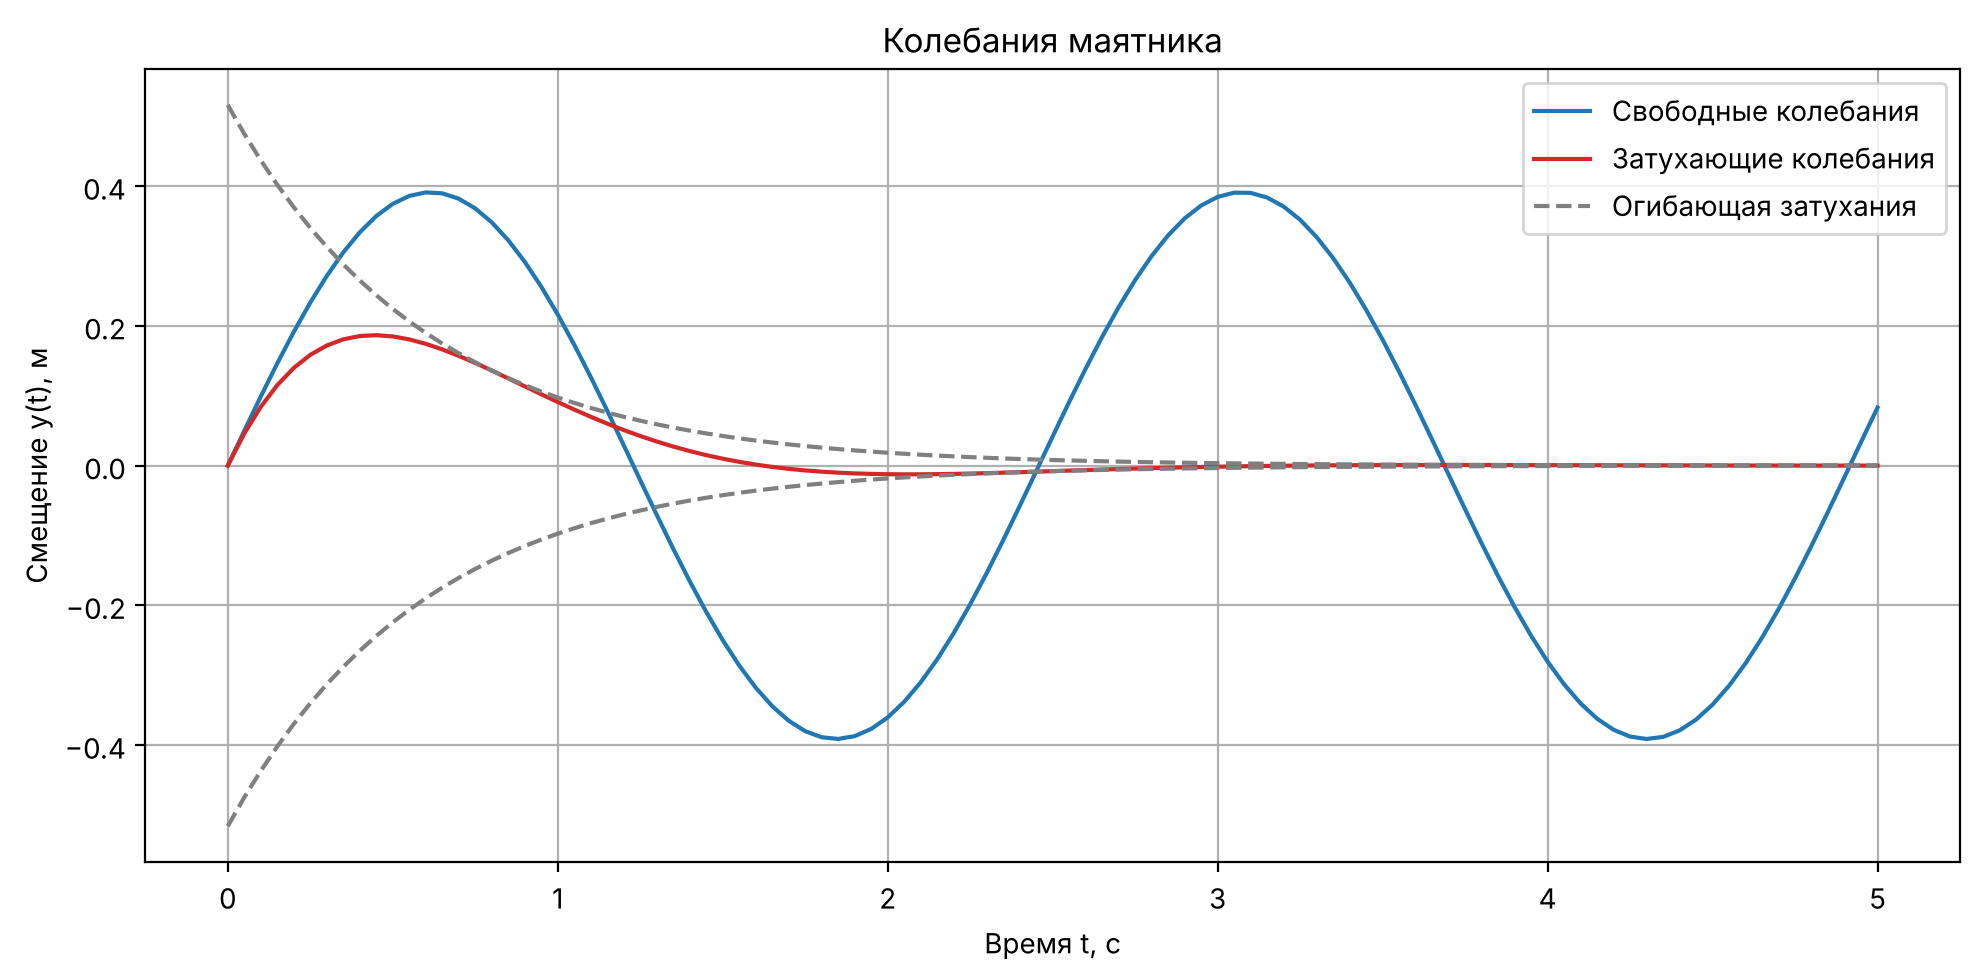

In [3]:
fig, ax = plt.subplots()
ax.plot(t, res['free'], label='Свободные колебания', color='tab:blue')
ax.plot(t, res['damped'], label='Затухающие колебания', color='tab:red')
ax.plot(t, res['envelope'], '--', color='gray', label='Огибающая затухания')
ax.plot(t, -res['envelope'], '--', color='gray')
ax.set_xlabel('Время t, с')
ax.set_ylabel('Смещение y(t), м')
ax.set_title('Колебания маятника')
ax.legend()
plt.tight_layout()
plt.show()

**Что видно:** свободные колебания идут с постоянной амплитудой, затухающие быстро уменьшаются внутри огибающей. Частота затухающих колебаний ω меньше ω₀, то есть сопротивление ещё и немного замедляет маятник.

## 4. Как влияет коэффициент сопротивления k

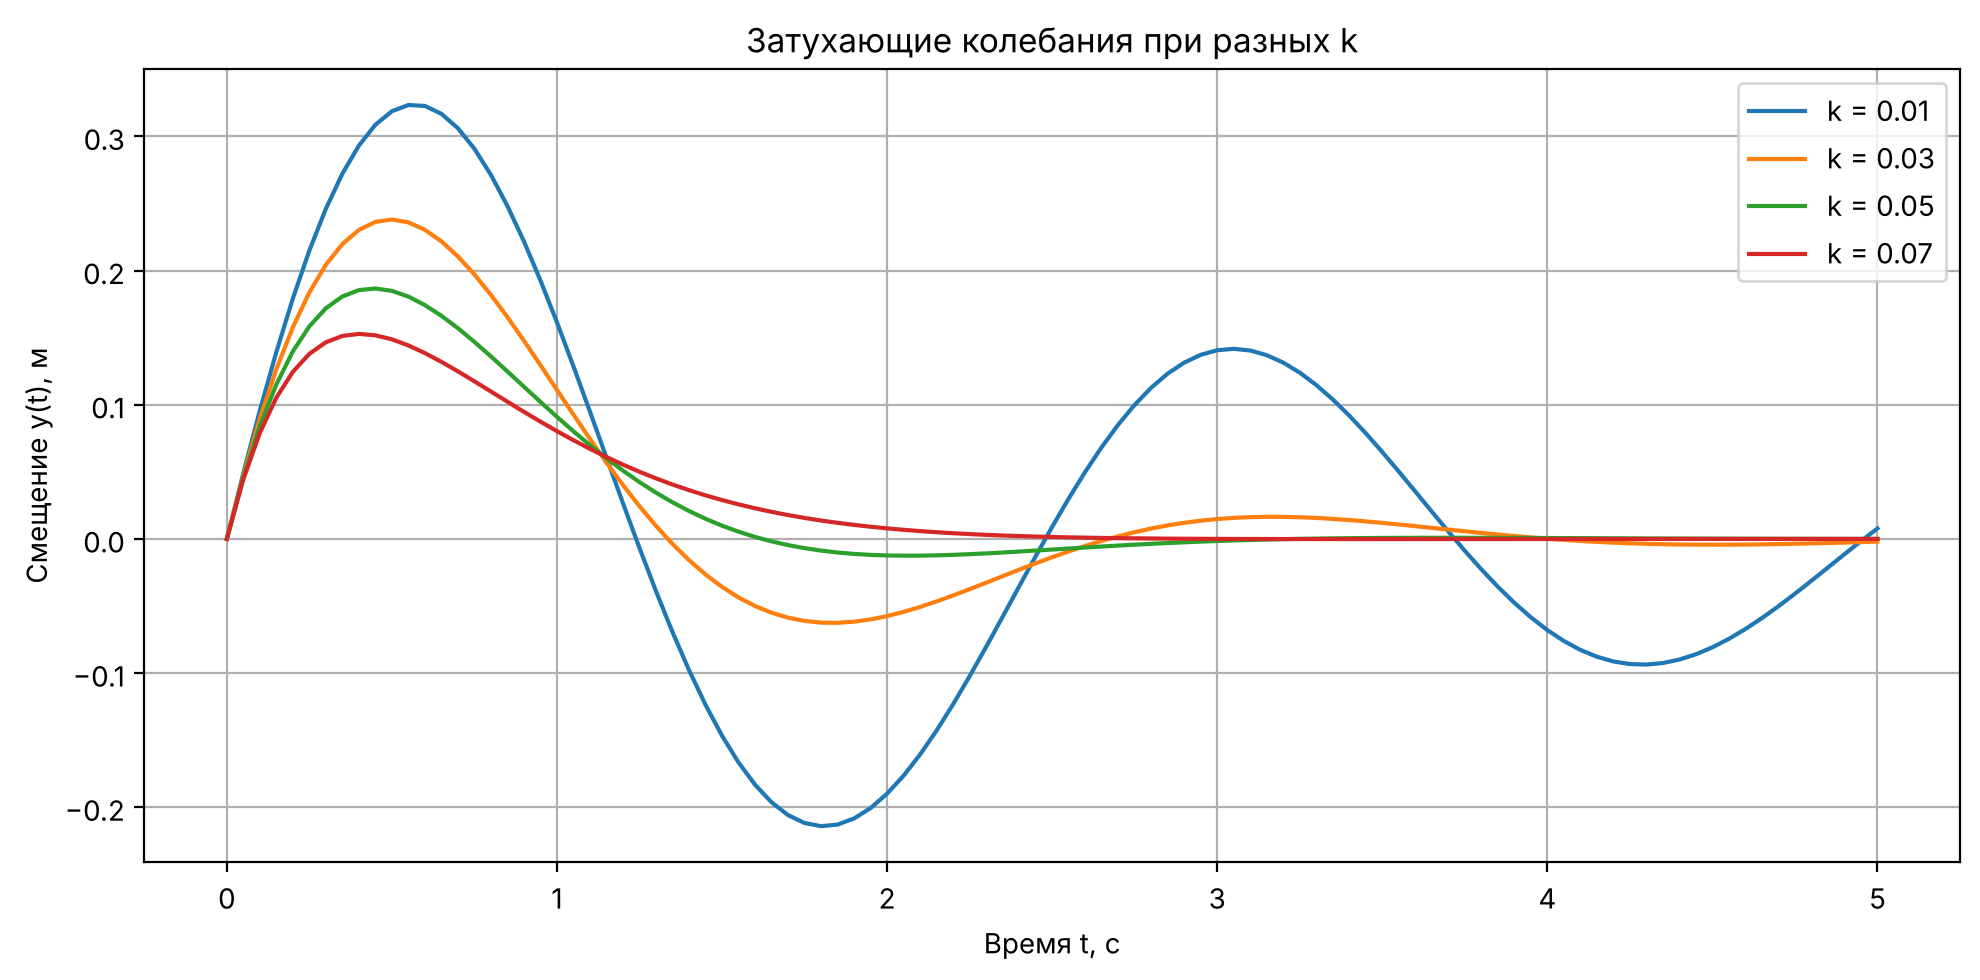

In [4]:
ks = [0.01, 0.03, 0.05, 0.07]

fig, ax = plt.subplots()
for kk in ks:
    r = model(kk)
    ax.plot(t, r['damped'], label=f'k = {kk}')
ax.set_xlabel('Время t, с')
ax.set_ylabel('Смещение y(t), м')
ax.set_title('Затухающие колебания при разных k')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Числовые характеристики

In [5]:
import pandas as pd

rows = []
for kk in ks:
    r = model(kk)
    T = 2 * np.pi / r['omega']                      # период, с
    t_decay = np.log(1 / 0.05) / r['alpha']         # время, когда огибающая упадёт до 5% от начальной
    rows.append({
        'k': kk,
        'alpha, 1/с': round(r['alpha'], 3),
        'omega, рад/с': round(r['omega'], 3),
        'Период T, с': round(T, 3),
        'Время затухания до 5%, с': round(t_decay, 2),
    })

pd.DataFrame(rows)

,k,"alpha, 1/с","omega, рад/с","Период T, с","Время затухания до 5%, с"
0,0.01,0.333,2.534,2.479,8.99
1,0.03,1.000,2.352,2.671,3.00
2,0.05,1.667,1.938,3.242,1.80
3,0.07,2.333,1.043,6.021,1.28


## Выводы

- Чем больше коэффициент сопротивления *k*, тем больше α и тем быстрее затухают колебания.
- При росте α частота ω уменьшается, период колебаний увеличивается.
- Если α ≥ ω₀, колебаний нет вообще (функция `model` в этом случае выдаёт ошибку).

## Что можно улучшить
- сравнить с численным решением дифференциального уравнения (`scipy.integrate.solve_ivp`);
- добавить интерактивные ползунки для параметров (`ipywidgets`);
- построить фазовый портрет (скорость от смещения).